In [ ]:
!pip install pandas
!pip install openpyxl
!pip install seaborn
!pip install matplotlib
!pip install numpy
!pip install scikit-learn


In [ ]:

# Import Library
import pandas as pd        # untuk olah data tabel (CSV, Excel, dll)
import numpy as np       # untuk operasi numerik & array
import matplotlib.pyplot as plt   # untuk visualisasi grafik dasar
import seaborn as sns      # untuk visualisasi grafik yang lebih bagus
import sklearn             # untuk machine learning kayak regresi, klasifikasi, pca
import scipy

In [ ]:
#IMPORT DATA
from google.colab import files
uploaded = files.upload()

Saving Dataset Pasien Rumah Sakit (1).csv to Dataset Pasien Rumah Sakit (1) (1).csv


In [ ]:
#UBAH MENJADI DATA FRAME DI COLLAB
import pandas as pd
data = pd.read_csv('Dataset Pasien Rumah Sakit (1).csv')

data

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25,Other,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,NaN,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35,Other,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,NaN,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,NaN,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70,Other,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,forty,Other,NaN,LISINOPRIL,01/15/2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,forty,Other,NaN,ALBUTEROL,2020/02/20,110/70,NaN,name@hospital.org,NaN
998,jane smith,25,Male,NaN,ALBUTEROL,"April 5, 2018",110/70,200.0,NaN,


In [ ]:
# Informasi data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Patient Name    1000 non-null   object 
 1   Age             841 non-null    object 
 2   Gender          1000 non-null   object 
 3   Condition       794 non-null    object 
 4   Medication      1000 non-null   object 
 5   Visit Date      1000 non-null   object 
 6   Blood Pressure  834 non-null    object 
 7   Cholesterol     769 non-null    float64
 8   Email           616 non-null    object 
 9   Phone Number    821 non-null    object 
dtypes: float64(1), object(9)
memory usage: 78.3+ KB


In [ ]:
#jumlah baris yang duplikat
data.duplicated().sum()


np.int64(0)

In [ ]:
#melihat jumlah missing value
data.isna().sum()

,0
Patient Name,0
Age,159
Gender,0
Condition,206
Medication,0
Visit Date,0
Blood Pressure,166
Cholesterol,231
Email,384
Phone Number,179


In [ ]:
#cek jumlah karakter unik
unique=data.nunique()
unique

,0
Patient Name,10
Age,5
Gender,3
Condition,4
Medication,5
Visit Date,5
Blood Pressure,4
Cholesterol,4
Email,3
Phone Number,4


In [ ]:
#cek karakter unik di salah satu kolom, nan tetap masuk, tapi tidak dihitung sebagai karakter unik
data['Patient Name'].unique()

array([' david lee ', ' emily davis ', ' laura martinez ',
       ' michael wilson ', ' mary clark ', ' robert brown ',
       ' sarah johnson ', ' jane smith ', ' john doe ', ' james taylor '],
      dtype=object)

In [ ]:
#cek karakter unik di salah satu kolom, nan tetap masuk, tapi tidak dihitung sebagai karakter unik
data['Age'].unique()

array(['25', nan, '35', '60', 'forty', '70'], dtype=object)

In [ ]:
#cek karakter unik di salah satu kolom, nan tetap masuk, tapi tidak dihitung sebagai karakter unik
data['Gender'].unique()

array(['Other', 'Male', 'Female'], dtype=object)

In [ ]:
#cek karakter unik di salah satu kolom, nan tetap masuk, tapi tidak dihitung sebagai karakter unik
data['Condition'].unique()

array(['Heart Disease', 'Diabetes', 'Asthma', 'Hypertension', nan],
      dtype=object)

In [ ]:
data['Medication'].unique()

array(['METFORMIN', 'NONE', 'ALBUTEROL', 'LISINOPRIL', 'ATORVASTATIN'],
      dtype=object)

In [ ]:
data['Visit Date'].unique()

array(['01/15/2020', 'April 5, 2018', '2019.12.01', '2020/02/20',
       '03-25-2019'], dtype=object)

In [ ]:
data['Blood Pressure'].unique()

array(['140/90', '120/80', '110/70', nan, '130/85'], dtype=object)

In [ ]:
data['Cholesterol'].unique()

array([200., 160.,  nan, 180., 220.])

In [ ]:
data['Email'].unique()

array(['name@hospital.org', nan, 'contact@domain.com',
       'patient@example.com'], dtype=object)

In [ ]:
data['Phone Number'].unique()

array(['555-555-5555', nan, ' ', '123-456-7890', '098-765-4321'],
      dtype=object)

# NOMOR 1

## Data Cleaning


In [ ]:
# Replace 'forty' with 40 in the 'Age' column
data['Age'] = data['Age'].replace('forty', 40)

# Convert the 'Age' column to numeric, coercing errors to NaN
data['Age'] = pd.to_numeric(data['Age'], errors='coerce')

# Calculate the median of the 'Age' column
median_age = data['Age'].median()

# Replace NaN values in the 'Age' column with the median
data['Age'] = data['Age'].fillna(median_age)

data

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25.0,Other,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,40.0,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35.0,Other,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,40.0,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Other,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,40.0,Other,NaN,LISINOPRIL,01/15/2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,40.0,Other,NaN,ALBUTEROL,2020/02/20,110/70,NaN,name@hospital.org,NaN
998,jane smith,25.0,Male,NaN,ALBUTEROL,"April 5, 2018",110/70,200.0,NaN,


In [ ]:
# Calculate the modus of the 'Gender' column
modus_gender = data['Gender'].mode()[0]  # Get the first mode if there are multiple

# Replace 'Other' values in the 'Gender' column with the modus
data['Gender'] = data['Gender'].replace('Other', modus_gender)

data

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25.0,Female,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,40.0,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35.0,Female,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,40.0,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,40.0,Female,NaN,LISINOPRIL,01/15/2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,40.0,Female,NaN,ALBUTEROL,2020/02/20,110/70,NaN,name@hospital.org,NaN
998,jane smith,25.0,Male,NaN,ALBUTEROL,"April 5, 2018",110/70,200.0,NaN,


In [ ]:
#menghitung jumlah kondisi unik (Condition) yang muncul untuk setiap obat (Medication).
data.groupby('Medication')['Condition'].nunique()


,Condition
Medication,
ALBUTEROL,4
ATORVASTATIN,4
LISINOPRIL,4
METFORMIN,4
NONE,4


In [ ]:
#melakukan imputasi dengan modus namun menyesuaikan modus penyakit di tiap jenis obat
condition_mapping = (
    data[data['Medication'] != 'NONE']
    .groupby('Medication')['Condition']
    .agg(lambda x: x.mode()[0] if not x.mode().empty else None)
    .to_dict()
)
# Fill NaN values in 'Condition' based on the mapping, but only if Medication is not 'NONE' and Condition was originally NaN
data['Condition'] = data.apply(lambda row: condition_mapping.get(row['Medication'], row['Condition']) if pd.isna(row['Condition']) and row['Medication'] != 'NONE' else row['Condition'], axis=1)

data.isna().sum()

,0
Patient Name,0
Age,0
Gender,0
Condition,52
Medication,0
Visit Date,0
Blood Pressure,166
Cholesterol,231
Email,384
Phone Number,179


In [ ]:
datahalf = data.copy()
datahalf #datahalf means udah separuh diproses

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25.0,Female,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,40.0,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35.0,Female,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,40.0,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01/15/2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,2020/02/20,110/70,NaN,name@hospital.org,NaN
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,"April 5, 2018",110/70,200.0,NaN,


In [ ]:
datahalf.iloc[7]  #Validasi di row ke 7 apakah udah berubah apa belum

,7
Patient Name,david lee
Age,60.0
Gender,Female
Condition,NaN
Medication,NONE
Visit Date,2020/02/20
Blood Pressure,NaN
Cholesterol,NaN
Email,name@hospital.org
Phone Number,NaN


In [ ]:
datahalf['Visit Date'] = datahalf['Visit Date'].astype(str).str.strip()
datahalf  #Membersihkan kolom Visit Date dari spasi dan memastikan semua nilainya bertipe string sebelum diolah lebih lanjut

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25.0,Female,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,40.0,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35.0,Female,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,40.0,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01/15/2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,2020/02/20,110/70,NaN,name@hospital.org,NaN
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,"April 5, 2018",110/70,200.0,NaN,


In [ ]:
import pandas as pd

# Define a list of possible date formats
date_formats = ['%m/%d/%Y', '%B %d, %Y', '%Y.%m.%d', '%Y/%m/%d', '%m-%d-%Y']

# Function to parse date trying multiple formats
def parse_date(date_str):
    for fmt in date_formats:
        try:
            return pd.to_datetime(date_str, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT # Return NaT for unparseable dates

# Apply the parsing function to the 'Visit Date' column
datahalf['Visit Date'] = datahalf['Visit Date'].apply(parse_date)

# ubah tampilannya ke format MM-DD-YYYY dengan tanda "-"
datahalf['Visit Date'] = datahalf['Visit Date'].dt.strftime('%m-%d-%Y')

display(datahalf)

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,120/80,200.0,NaN,NaN
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,110/70,160.0,contact@domain.com,NaN
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,110/70,180.0,NaN,
...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,NaN,160.0,NaN,123-456-7890
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,110/70,NaN,name@hospital.org,NaN
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,110/70,200.0,NaN,


In [ ]:
datahalf[['Systolic', 'Diastolic']] = datahalf['Blood Pressure'].str.split('/', expand=True)
datahalf #Split BP jadi Systol dan diastol biar mudah dalam membaca data (agar bisa numerik)

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,140/90,200.0,name@hospital.org,555-555-5555,140,90
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,120/80,200.0,NaN,NaN,120,80
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,110/70,160.0,contact@domain.com,NaN,110,70
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,110/70,NaN,name@hospital.org,555-555-5555,110,70
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,110/70,180.0,NaN,,110,70
...,...,...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,110/70,NaN,name@hospital.org,NaN,110,70
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,NaN,160.0,NaN,123-456-7890,NaN,NaN
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,110/70,NaN,name@hospital.org,NaN,110,70
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,110/70,200.0,NaN,,110,70


In [ ]:
# menghapus kolom blood pressure karena udah di split tadi
datahalf = datahalf.drop('Blood Pressure', axis=1)
datahalf

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Email,Phone Number,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,name@hospital.org,555-555-5555,140,90
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,NaN,NaN,120,80
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,contact@domain.com,NaN,110,70
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,NaN,name@hospital.org,555-555-5555,110,70
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,NaN,,110,70
...,...,...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,NaN,name@hospital.org,NaN,110,70
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,NaN,123-456-7890,NaN,NaN
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,NaN,name@hospital.org,NaN,110,70
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,NaN,,110,70


In [ ]:
#cek missing value
datahalf.isna().sum()

,0
Patient Name,0
Age,0
Gender,0
Condition,52
Medication,0
Visit Date,0
Cholesterol,231
Email,384
Phone Number,179
Systolic,166


In [ ]:
#Email Phone number kan gada pengaruh ke kondisi(secara logika) jadi kita coba uji pengaruhnya
# Correlation Test : Chi-Square Test
# Kita akan lakukan pengujian korelasi dengan Data Nominal (Kategorik) dengan Chi-Square Test
import scipy.stats as stats

# membuat tabel kontingensi
contingency_table = pd.crosstab(datahalf['Email'], datahalf['Condition'])
print(contingency_table)

Condition            Asthma  Diabetes  Heart Disease  Hypertension
Email                                                             
contact@domain.com       54        62             59            32
name@hospital.org        38        65             43            40
patient@example.com      44        64             48            36


In [ ]:
import pandas as pd
import scipy.stats as stats

# Uji chi-square
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

# Hitung nilai kritis (misal α = 0.05)
alpha = 0.05
critical_value = stats.chi2.ppf(1 - alpha, dof)

print(f"Chi-Square Score : {chi2}")
print(f"P-Value          : {p}")
print(f"Degrees of Freedom (df): {dof}")
print(f"Chi-Square Critical Value (α={alpha}) : {critical_value}")
print("Expected Frequencies Table:")
print(pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns))

# Keputusan
if chi2 > critical_value:
    print(" Tolak H0: Ada hubungan signifikan")
else:
    print(" Gagal tolak H0: Tidak ada hubungan signifikan")

Chi-Square Score : 5.257838232782441
P-Value          : 0.5111940529302104
Degrees of Freedom (df): 6
Chi-Square Critical Value (α=0.05) : 12.591587243743977
Expected Frequencies Table:
Condition               Asthma   Diabetes  Heart Disease  Hypertension
Email                                                                 
contact@domain.com   48.123077  67.584615      53.076923     38.215385
name@hospital.org    43.241026  60.728205      47.692308     34.338462
patient@example.com  44.635897  62.687179      49.230769     35.446154
 Gagal tolak H0: Tidak ada hubungan signifikan


In [ ]:
# Correlation Test : Chi-Square Test
# Kita akan lakukan pengujian korelasi dengan Data Nominal (Kategorik) dengan Chi-Square Test
import scipy.stats as stats

# membuat tabel kontingensi
contingency_table = pd.crosstab(datahalf['Phone Number'], datahalf['Condition'])
print(contingency_table)

Condition     Asthma  Diabetes  Heart Disease  Hypertension
Phone Number                                               
                  46        50             52            39
098-765-4321      31        67             43            26
123-456-7890      53        83             60            41
555-555-5555      46        61             42            35


In [ ]:
import pandas as pd
import scipy.stats as stats

# Uji chi-square
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

# Hitung nilai kritis (misal α = 0.05)
alpha = 0.05
critical_value = stats.chi2.ppf(1 - alpha, dof)

print(f"Chi-Square Score : {chi2}")
print(f"P-Value          : {p}")
print(f"Degrees of Freedom (df): {dof}")
print(f"Chi-Square Critical Value (α={alpha}) : {critical_value}")
print("Expected Frequencies Table:")
print(pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns))

# Keputusan
if chi2 > critical_value:
    print(" Tolak H0: Ada hubungan signifikan")
else:
    print(" Gagal tolak H0: Tidak ada hubungan signifikan")

Chi-Square Score : 9.318850441065706
P-Value          : 0.40837727617498204
Degrees of Freedom (df): 9
Chi-Square Critical Value (α=0.05) : 16.918977604620448
Expected Frequencies Table:
Condition        Asthma   Diabetes  Heart Disease  Hypertension
Phone Number                                                   
              42.467097  62.976774      47.534194     34.021935
098-765-4321  37.925161  56.241290      42.450323     30.383226
123-456-7890  53.821935  79.815484      60.243871     43.118710
555-555-5555  41.785806  61.966452      46.771613     33.476129
 Gagal tolak H0: Tidak ada hubungan signifikan


hapus email dan phone number


In [ ]:
# menghapus kolom email dan phone number
datahalf = datahalf.drop(['Email','Phone Number'], axis=1)
datahalf

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140,90
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120,80
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110,70
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,NaN,110,70
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110,70
...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,NaN,110,70
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,NaN,NaN
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,NaN,110,70
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110,70


In [ ]:
datahalf['Cholesterol'] = datahalf.groupby('Condition')['Cholesterol'].transform(
    lambda x: x.fillna(x.median())
)
datahalf  #missing value kolesterol diganti pake median

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140,90
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120,80
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110,70
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110,70
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110,70
...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110,70
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,NaN,NaN
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110,70
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110,70


In [ ]:
#cek missing value
datahalf.isna().sum()

,0
Patient Name,0
Age,0
Gender,0
Condition,52
Medication,0
Visit Date,0
Cholesterol,52
Systolic,166
Diastolic,166


In [ ]:
# Convert Systolic and Diastolic columns to numeric, coercing errors to NaN
datahalf['Systolic'] = pd.to_numeric(datahalf['Systolic'], errors='coerce')
datahalf['Diastolic'] = pd.to_numeric(datahalf['Diastolic'], errors='coerce')

# Fill NaN values in 'Systolic' and 'Diastolic' with the median of each group
datahalf['Systolic'] = datahalf.groupby('Condition')['Systolic'].transform(
    lambda x: x.fillna(x.median())
)
datahalf['Diastolic'] = datahalf.groupby('Condition')['Diastolic'].transform(
    lambda x: x.fillna(x.median())
)

datahalf

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0
...,...,...,...,...,...,...,...,...,...
995,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0
996,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0
997,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0
998,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0


In [ ]:
#cek missing value
datahalf.isna().sum()

,0
Patient Name,0
Age,0
Gender,0
Condition,52
Medication,0
Visit Date,0
Cholesterol,52
Systolic,52
Diastolic,52


In [ ]:
#drop baris dengan missing value
datahalf = datahalf.dropna()
datahalf.isna().sum()

,0
Patient Name,0
Age,0
Gender,0
Condition,0
Medication,0
Visit Date,0
Cholesterol,0
Systolic,0
Diastolic,0


In [ ]:
#reset nomor index setelah drop baris
datahalf.reset_index(inplace=True)
datahalf.drop('index',axis=1,inplace=True)
datahalf

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0
...,...,...,...,...,...,...,...,...,...
943,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0
944,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0
945,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0
946,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0


In [ ]:
dataakhir = datahalf.copy()
dataakhir

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0
...,...,...,...,...,...,...,...,...,...
943,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0
944,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0
945,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0
946,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0


In [ ]:
#jumlah baris yang duplikat
dataakhir.duplicated().sum()

np.int64(2)

In [ ]:
#drop baris duplikat
databaru = dataakhir.drop_duplicates()
#reset nomor index setelah drop baris duplikat
databaru.reset_index(inplace=True)
databaru.drop('index',axis=1,inplace=True)
databaru

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0
...,...,...,...,...,...,...,...,...,...
941,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0
942,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0
943,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0
944,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0


In [ ]:
databaru['Patient Name'].unique()

array([' david lee ', ' emily davis ', ' laura martinez ',
       ' michael wilson ', ' mary clark ', ' robert brown ',
       ' sarah johnson ', ' jane smith ', ' john doe ', ' james taylor '],
      dtype=object)

In [ ]:
databaru.to_csv('cleaned_patient_data.csv', index=False)
print("DataFrame saved to cleaned_patient_data2.csv")

DataFrame saved to cleaned_patient_data2.csv


In [ ]:
#menambah kolom disease status adjusted untuk melakukan step no 2
def categorize_disease_status(row):
    cholesterol = row['Cholesterol']
    systolic = row['Systolic']
    diastolic = row['Diastolic']

    is_parah = 0
    if cholesterol >= 240:
        is_parah += 1
    if systolic >= 160:
        is_parah += 1
    if diastolic >= 100:
        is_parah += 1

    if is_parah >= 2 or any([cholesterol >= 240, systolic >= 160, diastolic >= 100]):
        return 'PARAH'
    elif 200 <= cholesterol <= 239 or 140 <= systolic <= 159 or 90 <= diastolic <= 99:
        return 'SEDANG'
    elif cholesterol < 200 and systolic < 140 and diastolic < 90:
        return 'TIDAK PARAH'
    else:
        return 'UNKNOWN' # Handle cases that don't fit any category

def adjust_disease_status_by_age(row):
    age = row['Age']
    disease_status = row['Disease_status']

    if age > 40:
        if disease_status == 'TIDAK PARAH':
            return 'SEDANG'
        elif disease_status == 'SEDANG':
            return 'PARAH'
        elif disease_status == 'PARAH':
            return 'PARAH'  # Stays PARAH
        else:
            return disease_status # Handle UNKNOWN or other statuses
    else:
        return disease_status # Status remains the same for age <= 40

databaru['Disease_status'] = databaru.apply(categorize_disease_status, axis=1)
databaru['Disease_status_adjusted'] = databaru.apply(adjust_disease_status_by_age, axis=1)

display(databaru[['Cholesterol', 'Systolic', 'Diastolic', 'Disease_status', 'Disease_status_adjusted']].head())

,Cholesterol,Systolic,Diastolic,Disease_status,Disease_status_adjusted
0,200.0,140.0,90.0,SEDANG,SEDANG
1,200.0,120.0,80.0,SEDANG,SEDANG
2,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
3,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
4,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH


In [ ]:
#menampilkan data setelah cleaning dan penambahan kolom baru
databaru

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic,Disease_status,Disease_status_adjusted
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0,SEDANG,SEDANG
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0,SEDANG,SEDANG
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
...,...,...,...,...,...,...,...,...,...,...,...
941,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0,SEDANG,PARAH
942,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0,TIDAK PARAH,TIDAK PARAH
943,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH
944,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0,SEDANG,SEDANG


#NOMOR 2

## Feature Selection

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

# Define the desired mapping for Condition_Category
condition_mapping = {'Hypertension': 0, 'Diabetes': 1, 'Heart Disease': 2, 'Asthma': 3}

# Convert the 'Condition' column to categorical with the specified mapping
dataakhir['Condition_Category'] = dataakhir['Condition'].map(condition_mapping).astype('category')

# Define the desired mapping for Status_code
status_mapping = {'PARAH': 2, 'SEDANG': 1, 'TIDAK PARAH': 0}

# Create the new 'Status_code' column based on 'Disease_status_adjusted' with the specified mapping
databaru['Status_code'] = databaru['Disease_status_adjusted'].map(status_mapping).astype('category')

databaru.info()
databaru

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Patient Name             946 non-null    object  
 1   Age                      946 non-null    float64 
 2   Gender                   946 non-null    object  
 3   Condition                946 non-null    object  
 4   Medication               946 non-null    object  
 5   Visit Date               946 non-null    object  
 6   Cholesterol              946 non-null    float64 
 7   Systolic                 946 non-null    float64 
 8   Diastolic                946 non-null    float64 
 9   Disease_status           946 non-null    object  
 10  Disease_status_adjusted  946 non-null    object  
 11  Status_code              946 non-null    category
dtypes: category(1), float64(4), object(7)
memory usage: 82.5+ KB


,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic,Disease_status,Disease_status_adjusted,Status_code
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0,SEDANG,SEDANG,1
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0,SEDANG,SEDANG,1
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
...,...,...,...,...,...,...,...,...,...,...,...,...
941,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0,SEDANG,PARAH,2
942,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0,TIDAK PARAH,TIDAK PARAH,0
943,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
944,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0,SEDANG,SEDANG,1


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# Select features (numerical columns excluding the target)
X = databaru[['Age', 'Cholesterol', 'Systolic', 'Diastolic']]

# Select the target variable
y = databaru['Status_code']

# Display the features and target
print("Features (X):")
display(X.head())
print("\nTarget (y):")
display(y.head())

Features (X):


,Age,Cholesterol,Systolic,Diastolic
0,25.0,200.0,140.0,90.0
1,40.0,200.0,120.0,80.0
2,35.0,160.0,110.0,70.0
3,40.0,180.0,110.0,70.0
4,40.0,180.0,110.0,70.0



Target (y):


,Status_code
0,1
1,1
2,0
3,0
4,0


In [ ]:
#mengetahui berapa banyak sampel dari tiap kelas 0,1,2
print(y.value_counts())



Status_code
1    496
0    280
2    170
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Pisahkan fitur dan target
X = databaru[['Age', 'Cholesterol', 'Systolic', 'Diastolic']]  # Select feature columns
y = databaru['Status_code']  # Select the target column
X

,Age,Cholesterol,Systolic,Diastolic
0,25.0,200.0,140.0,90.0
1,40.0,200.0,120.0,80.0
2,35.0,160.0,110.0,70.0
3,40.0,180.0,110.0,70.0
4,40.0,180.0,110.0,70.0
...,...,...,...,...
941,70.0,200.0,110.0,70.0
942,40.0,160.0,130.0,85.0
943,40.0,180.0,110.0,70.0
944,25.0,200.0,110.0,70.0


In [ ]:
y

,Status_code
0,1
1,1
2,0
3,0
4,0
...,...
941,2
942,0
943,0
944,1


In [ ]:
# Buat dan latih model Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)


RandomForestClassifier(random_state=42)

In [ ]:
# Ambil skor importance tiap fitur
importances = model.feature_importances_

# Buat DataFrame untuk hasil importance
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)


       Feature  Importance
1  Cholesterol    0.397629
0          Age    0.377844
2     Systolic    0.123288
3    Diastolic    0.101239


In [ ]:
# Menentukan threshold untuk seleksi fitur
threshold = 0.1  # Threshold dapat diganti ganti sesuai dengan referensi masing masing
not_selected_features = feature_importance_df[feature_importance_df['Importance'] <= threshold]['Feature'].values

print("\nFitur yang tidak dipilih:", not_selected_features)


Fitur yang tidak dipilih: []


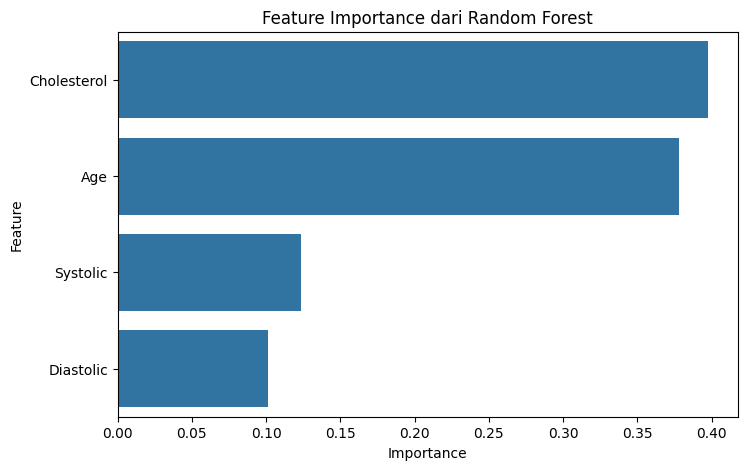

In [ ]:
#Visualisasi feature importance
plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance dari Random Forest')
plt.show()

## Feature Extraction

In [ ]:
import pandas as pd
import numpy as np
from sklearn import decomposition # Dipakai untuk metode dekomposisi, memecah data menjadi komponen penting.
from sklearn.preprocessing import StandardScaler

In [ ]:
dataext = databaru.copy()
dataext

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic,Disease_status,Disease_status_adjusted,Status_code
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0,SEDANG,SEDANG,1
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0,SEDANG,SEDANG,1
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
...,...,...,...,...,...,...,...,...,...,...,...,...
941,mary clark,70.0,Female,Asthma,ALBUTEROL,03-25-2019,200.0,110.0,70.0,SEDANG,PARAH,2
942,mary clark,40.0,Female,Diabetes,LISINOPRIL,01-15-2020,160.0,130.0,85.0,TIDAK PARAH,TIDAK PARAH,0
943,laura martinez,40.0,Female,Diabetes,ALBUTEROL,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
944,jane smith,25.0,Male,Diabetes,ALBUTEROL,04-05-2018,200.0,110.0,70.0,SEDANG,SEDANG,1


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Select only numerical columns for scaling
numerical_dataext = dataext.select_dtypes(include=np.number)
scaled_data = scaler.fit_transform(numerical_dataext)  # Scale only the numerical data
data_pca = pd.DataFrame(scaled_data, columns=numerical_dataext.columns, index=numerical_dataext.index) # Create DataFrame with scaled numerical data
data_pca.head()

,Age,Cholesterol,Systolic,Diastolic
0,-1.301245,0.587001,1.325223,1.156906
1,-0.316725,0.587001,-0.548710,-0.267210
2,-0.644899,-1.417704,-1.485676,-1.691325
3,-0.316725,-0.415351,-1.485676,-1.691325
4,-0.316725,-0.415351,-1.485676,-1.691325


In [ ]:
# Hitung kovarians data
covariance_matrix = np.cov(data_pca.T)

print("Covariance Matrix:")
covariance_matrix

Covariance Matrix:


array([[ 1.0010582 , -0.01751784, -0.03731314, -0.03106222],
       [-0.01751784,  1.0010582 ,  0.04913056,  0.04599341],
       [-0.03731314,  0.04913056,  1.0010582 ,  0.98353711],
       [-0.03106222,  0.04599341,  0.98353711,  1.0010582 ]])

In [ ]:
eigen_val, eigen_vec = np.linalg.eig(covariance_matrix)
print("Eigen Value :\n", eigen_val, "\n")
print("Eigen Vector :\n", eigen_vec, "\n")


Eigen Value :
 [1.99164082 1.01177353 0.98332195 0.0174965 ] 

Eigen Vector :
 [[-0.04984566  0.73212477  0.67932968 -0.00446398]
 [ 0.06853989 -0.6760621   0.73364673  0.00218846]
 [ 0.70469624  0.05541405 -0.01266102 -0.70722853]
 [ 0.70442949  0.06215014 -0.01064728  0.70696753]] 



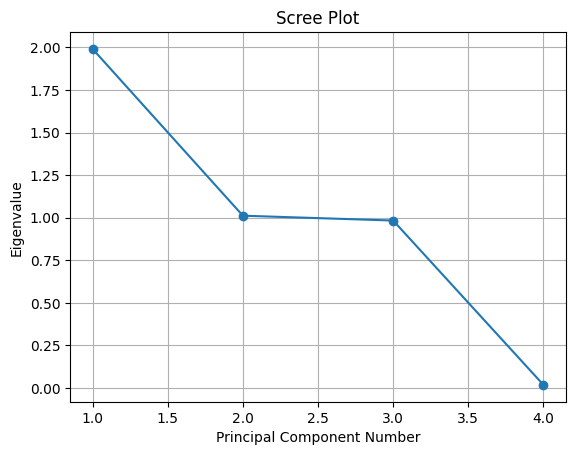

In [ ]:
import matplotlib.pyplot as plt

# Scree Plot
plt.plot(range(1, len(eigen_val) + 1), eigen_val, marker='o') # +1 agar index mulai dari 1
plt.title('Scree Plot')
plt.xlabel('Principal Component Number')
plt.ylabel('Eigenvalue')
plt.grid()
plt.show()

### Proporsi Varians

In [ ]:
var_explained = []
for i in eigen_val :
    var_explained.append(float(i/sum(eigen_val))*100)
print(var_explained)

[49.738387237409796, 25.267600032071652, 24.557062547297217, 0.4369501832213393]


In [ ]:
cumulative_var_explained=np.cumsum(var_explained)
cumulative_var_explained

array([ 49.73838724,  75.00598727,  99.56304982, 100.        ])

In [ ]:
# Buat PCA berdasarkan threshodl proporsi varians >= 90
n_components = np.argmax(cumulative_var_explained >= 90) + 1
pca = decomposition.PCA(n_components=n_components)
principal_components = pca.fit_transform(data_pca) # Mengubah koordinat data dari sumbu lama (fitur asli) ke sumbu baru (PC).

# Buat data frame untuk PC nya
principal_df = pd.DataFrame(data=principal_components, columns=['PC' + str(i) for i in range(1, n_components + 1)])

print("Number of components for 90% variance:", n_components)
principal_df

Number of components for 90% variance: 3


,PC1,PC2,PC3
0,1.853932,-1.204185,-0.482419
1,-0.518884,-0.675745,0.225283
2,-2.303393,0.298866,-1.441374
3,-2.251050,-0.138523,-0.483064
4,-2.251050,-0.138523,-0.483064
...,...,...,...
941,-2.280497,0.625407,1.589936
942,0.505585,0.775736,-1.264907
943,-2.251050,-0.138523,-0.483064
944,-2.133275,-1.536967,-0.416504


In [ ]:
import numpy as np

print("Persamaan PCA (Linear Combination):\n")
for i in range(n_components):
    equation = f"PC{i+1} = "
    for j in range(len(data_pca.columns)): # Iterate through the columns of the scaled data
        coef = round(pca.components_[i][j], 3) # Kontribusi fitur ke-j dalam PC ke-i.
        feature = data_pca.columns[j] # Get feature name from scaled data
        term = f"{coef:+}*{feature}"
        equation += term + " "
    print(equation)

Persamaan PCA (Linear Combination):

PC1 = -0.05*Age +0.069*Cholesterol +0.705*Systolic +0.704*Diastolic 
PC2 = +0.732*Age -0.676*Cholesterol +0.055*Systolic +0.062*Diastolic 
PC3 = +0.679*Age +0.734*Cholesterol -0.013*Systolic -0.011*Diastolic 


### kaiser rule

In [ ]:
print("Eigen Value :\n", eigen_val, "\n")

Eigen Value :
 [1.99164082 1.01177353 0.98332195 0.0174965 ] 



In [ ]:
# Buat PCA berdasarkan threshold Kaiser Rule, eigen value >= 1
# Hitung JUMLAH komponen dengan eigenvalue >= 1 (Kaiser rule)
n_components_1 = int(np.sum(eigen_val >= 1))

# Safety: kalau tidak ada yang >= 1, paksa ambil minimal 1 komponen
n_components_1 = max(n_components_1, 1)

pca = decomposition.PCA(n_components=n_components_1)
principal_components = pca.fit_transform(data_pca)

# Buat data frame untuk PC nya
principal_df = pd.DataFrame(data=principal_components, columns=['PC' + str(i) for i in range(1, n_components_1 + 1)])

print("Jumlah PC", n_components_1)
principal_df

Jumlah PC 2


,PC1,PC2
0,1.853932,-1.204185
1,-0.518884,-0.675745
2,-2.303393,0.298866
3,-2.251050,-0.138523
4,-2.251050,-0.138523
...,...,...
941,-2.280497,0.625407
942,0.505585,0.775736
943,-2.251050,-0.138523
944,-2.133275,-1.536967


In [ ]:
#Membuat persamaan PCA

import numpy as np

print("Persamaan PCA (Linear Combination):\n")
for i in range(n_components_1):
    equation = f"PC{i+1} = "
    for j in range(len(data_pca.columns)):
        coef = round(pca.components_[i][j], 3)
        feature = data_pca.columns[j]
        term = f"{coef:+}*{feature}"
        equation += term + " "
    print(equation)

Persamaan PCA (Linear Combination):

PC1 = -0.05*Age +0.069*Cholesterol +0.705*Systolic +0.704*Diastolic 
PC2 = +0.732*Age -0.676*Cholesterol +0.055*Systolic +0.062*Diastolic 


In [ ]:
dataext.to_csv('dataext.csv', index=False)
print("DataFrame dataext saved to dataext.csv")

DataFrame dataext saved to dataext.csv


# NOMOR 3

In [ ]:
# Step 1: Understand the data
print("First 5 rows of dataext:")
display(dataext.head())

print("\nInfo of dataext:")
dataext.info()

print("\nSummary statistics of dataext:")
display(dataext.describe())

First 5 rows of dataext:


,Patient Name,Age,Gender,Condition,Medication,Visit Date,Cholesterol,Systolic,Diastolic,Disease_status,Disease_status_adjusted,Status_code
0,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0,SEDANG,SEDANG,1
1,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0,SEDANG,SEDANG,1
2,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
3,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
4,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0



Info of dataext:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 946 entries, 0 to 945
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Patient Name             946 non-null    object  
 1   Age                      946 non-null    float64 
 2   Gender                   946 non-null    object  
 3   Condition                946 non-null    object  
 4   Medication               946 non-null    object  
 5   Visit Date               946 non-null    object  
 6   Cholesterol              946 non-null    float64 
 7   Systolic                 946 non-null    float64 
 8   Diastolic                946 non-null    float64 
 9   Disease_status           946 non-null    object  
 10  Disease_status_adjusted  946 non-null    object  
 11  Status_code              946 non-null    category
dtypes: category(1), float64(4), object(7)
memory usage: 82.5+ KB

Summary statistics of dataext:


,Age,Cholesterol,Systolic,Diastolic
count,946.000000,946.000000,946.000000,946.000000
mean,44.825581,188.287526,125.856237,81.876321
std,15.243915,19.963612,10.678389,7.025617
min,25.000000,160.000000,110.000000,70.000000
25%,35.000000,180.000000,120.000000,80.000000
50%,40.000000,180.000000,130.000000,85.000000
75%,60.000000,200.000000,130.000000,85.000000
max,70.000000,220.000000,140.000000,90.000000


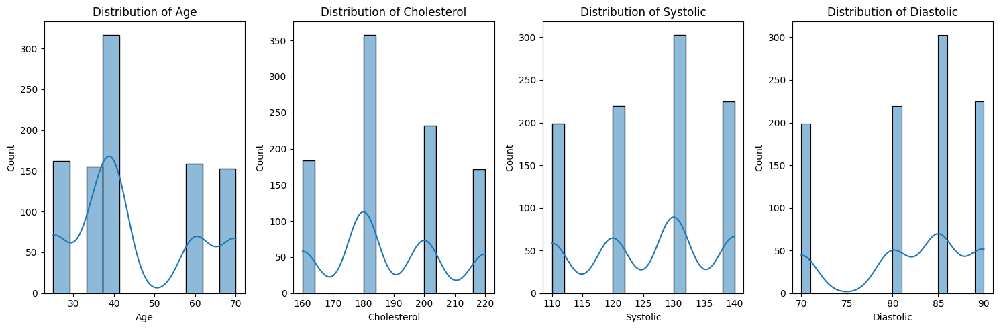

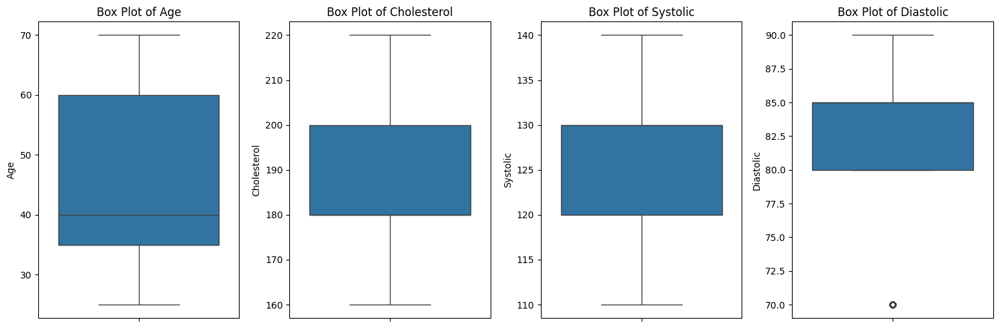

In [ ]:
# Step 2: Analyze distributions (Quantitative features)
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['Age', 'Cholesterol', 'Systolic', 'Diastolic']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, 4, i + 1)
    sns.histplot(dataext[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=dataext[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

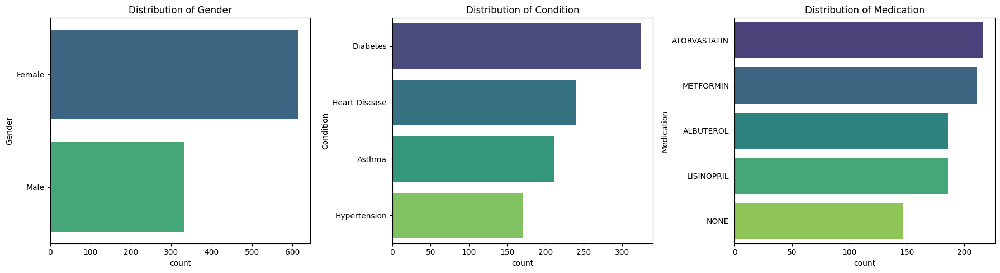

In [ ]:
# Step 2: Analyze distributions (Qualitative features)
import matplotlib.pyplot as plt
import seaborn as sns

categorical_cols = ['Gender', 'Condition', 'Medication']

plt.figure(figsize=(18, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 3, i + 1)
    sns.countplot(y=datafinal[col], order=datafinal[col].value_counts().index, palette='viridis')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# NOMOR 4

In [ ]:
datass = pd.read_csv('dataext.csv', header=None)
datass = datass.iloc[1:] # Drop the first row (which was the header)
datass.head()

,0,1,2,3,4,5,6,7,8,9,10,11
1,david lee,25.0,Female,Heart Disease,METFORMIN,01-15-2020,200.0,140.0,90.0,SEDANG,SEDANG,1
2,emily davis,40.0,Male,Diabetes,NONE,04-05-2018,200.0,120.0,80.0,SEDANG,SEDANG,1
3,laura martinez,35.0,Female,Asthma,METFORMIN,12-01-2019,160.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
4,michael wilson,40.0,Male,Diabetes,ALBUTEROL,01-15-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0
5,david lee,40.0,Female,Asthma,NONE,02-20-2020,180.0,110.0,70.0,TIDAK PARAH,TIDAK PARAH,0


In [ ]:
# Convert relevant columns to numeric, coercing errors to NaN
datass[6] = pd.to_numeric(datass[6], errors='coerce') # Cholesterol
datass[7] = pd.to_numeric(datass[7], errors='coerce') # Systolic
datass[8] = pd.to_numeric(datass[8], errors='coerce') # Diastolic

# Categorize Cholesterol
def categorize_cholesterol(cholesterol):
    if 160 <= cholesterol <= 199:
        return "Normal"
    elif 200 <= cholesterol <= 239:
        return "Tinggi"
    else:
        return "UNKNOWN" # Handle values outside the specified ranges

datass['Cholesterol_Category'] = datass[6].apply(categorize_cholesterol)

# Categorize Blood Pressure
def categorize_bp(systolic, diastolic):
    """Versi lebih ringkas dengan prioritas dari tinggi ke rendah"""

    if systolic > 180 or diastolic > 120:
        return "HYPERTENSIVE CRISIS"
    elif systolic >= 140 or diastolic >= 90:
        return "HIGH BLOOD PRESSURE STAGE 2"
    elif systolic >= 130 or diastolic >= 80:
        return "HIGH BLOOD PRESSURE STAGE 1"
    elif systolic >= 120:
        return "ELEVATED"
    else:
        return "NORMAL"

datass['Blood_Pressure_Category'] = datass.apply(lambda row: categorize_bp(row[7], row[8]), axis=1)

display(datass[[6, 'Cholesterol_Category', 7, 8, 'Blood_Pressure_Category']].head())

,6,Cholesterol_Category,7,8,Blood_Pressure_Category
1,200.0,Tinggi,140.0,90.0,HIGH BLOOD PRESSURE STAGE 2
2,200.0,Tinggi,120.0,80.0,HIGH BLOOD PRESSURE STAGE 1
3,160.0,Normal,110.0,70.0,NORMAL
4,180.0,Normal,110.0,70.0,NORMAL
5,180.0,Normal,110.0,70.0,NORMAL


In [ ]:
# Assuming the categorical columns are at specific indices based on the previous data loading
# If your column indices or types have changed, you might need to adjust this.
# Based on the output of cell zPtr8gTmXbpm, columns 2, 3, 4, 8, 9 are likely categorical.
categorical_datass = datass.iloc[:, [2, 3, 4, 9]] # Changed index 8 to 9 to use Disease_status_adjusted

# Include the newly created categorical columns
categorical_datass['Cholesterol_Category'] = datass['Cholesterol_Category']
categorical_datass['Blood_Pressure_Category'] = datass['Blood_Pressure_Category']

print("Categorical columns from datass:")
display(categorical_datass.head())

Categorical columns from datass:


,2,3,4,9,Cholesterol_Category,Blood_Pressure_Category
1,Female,Heart Disease,METFORMIN,SEDANG,Tinggi,HIGH BLOOD PRESSURE STAGE 2
2,Male,Diabetes,NONE,SEDANG,Tinggi,HIGH BLOOD PRESSURE STAGE 1
3,Female,Asthma,METFORMIN,TIDAK PARAH,Normal,NORMAL
4,Male,Diabetes,ALBUTEROL,TIDAK PARAH,Normal,NORMAL
5,Female,Asthma,NONE,TIDAK PARAH,Normal,NORMAL


In [ ]:
categorical_datass.to_csv('categorical_data.csv', index=False)
print("DataFrame categorical_datass saved to categorical_data.csv")

DataFrame categorical_datass saved to categorical_data.csv


## library Apriori

In [ ]:
!pip install apyori

In [ ]:

import warnings
warnings.filterwarnings('ignore')
import pandas as pd
from apyori import apriori


In [ ]:
#data preprocessing, rubah dataframe menjadi list
records=[]
for i in range(len(categorical_datass)):
    records.append([str(categorical_datass.values[i,j])for j in range(0,categorical_datass.shape[1]) if str(categorical_datass.values[i,j])!='nan'])
records

[['Female',
  'Heart Disease',
  'METFORMIN',
  'SEDANG',
  'Tinggi',
  'HIGH BLOOD PRESSURE STAGE 2'],
 ['Male',
  'Diabetes',
  'NONE',
  'SEDANG',
  'Tinggi',
  'HIGH BLOOD PRESSURE STAGE 1'],
 ['Female', 'Asthma', 'METFORMIN', 'TIDAK PARAH', 'Normal', 'NORMAL'],
 ['Male', 'Diabetes', 'ALBUTEROL', 'TIDAK PARAH', 'Normal', 'NORMAL'],
 ['Female', 'Asthma', 'NONE', 'TIDAK PARAH', 'Normal', 'NORMAL'],
 ['Male',
  'Hypertension',
  'METFORMIN',
  'SEDANG',
  'Normal',
  'HIGH BLOOD PRESSURE STAGE 2'],
 ['Male',
  'Hypertension',
  'LISINOPRIL',
  'TIDAK PARAH',
  'Normal',
  'HIGH BLOOD PRESSURE STAGE 1'],
 ['Female',
  'Heart Disease',
  'NONE',
  'SEDANG',
  'Normal',
  'HIGH BLOOD PRESSURE STAGE 2'],
 ['Female',
  'Diabetes',
  'ALBUTEROL',
  'SEDANG',
  'Tinggi',
  'HIGH BLOOD PRESSURE STAGE 2'],
 ['Male',
  'Asthma',
  'ATORVASTATIN',
  'SEDANG',
  'Tinggi',
  'HIGH BLOOD PRESSURE STAGE 1'],
 ['Male',
  'Heart Disease',
  'ATORVASTATIN',
  'SEDANG',
  'Tinggi',
  'HIGH BLOOD PRESSUR

In [ ]:
#Menemukan aturan asosiasi antar item dengan batas minimum support, conf,lift, dan length tertentu
association_rules=apriori(records,min_support=0.03,min_confidence=0.6,min_lift=1.1,min_length=2)
association_results=list(association_rules)
association_results

[RelationRecord(items=frozenset({'SEDANG', 'Asthma'}), support=0.1553911205073996, ordered_statistics=[OrderedStatistic(items_base=frozenset({'Asthma'}), items_add=frozenset({'SEDANG'}), confidence=0.6966824644549764, lift=1.2577511667450527)]),
 RelationRecord(items=frozenset({'Tinggi', 'Asthma'}), support=0.13953488372093023, ordered_statistics=[OrderedStatistic(items_base=frozenset({'Asthma'}), items_add=frozenset({'Tinggi'}), confidence=0.6255924170616114, lift=1.4648772934165455)]),
 RelationRecord(items=frozenset({'Normal', 'Diabetes'}), support=0.2219873150105708, ordered_statistics=[OrderedStatistic(items_base=frozenset({'Diabetes'}), items_add=frozenset({'Normal'}), confidence=0.6481481481481481, lift=1.1312696460297935)]),
 RelationRecord(items=frozenset({'Female', 'METFORMIN'}), support=0.160676532769556, ordered_statistics=[OrderedStatistic(items_base=frozenset({'METFORMIN'}), items_add=frozenset({'Female'}), confidence=0.7203791469194313, lift=1.1099001188693518)]),
 Relat

In [ ]:
print(len(association_results))

244


In [ ]:
for item in association_results:
    # Ambil informasi aturan asosiasi dari struktur data
    base_items = list(item[2][0][0])  # item asal (antecedent)
    add_items = list(item[2][0][1])   # item tambahan (consequent)

    # Convert ke string (asumsi satu item per sisi)
    base = ', '.join(map(str, base_items))
    add  = ', '.join(map(str, add_items))

    # Ambil nilai support, confidence, dan lift
    support = item[1]
    confidence = item[2][0][2]
    lift = item[2][0][3]

    # Print hasilnya dengan format yang konsisten
    print(f"Rule: {base} -> {add}") # 4 angka di belakang koma
    print(f"Support: {support:.4f}")
    print(f"Confidence: {confidence:.4f}")
    print(f"Lift: {lift:.4f}")
    print("="*40)

Rule: Asthma -> SEDANG
Support: 0.1554
Confidence: 0.6967
Lift: 1.2578
Rule: Asthma -> Tinggi
Support: 0.1395
Confidence: 0.6256
Lift: 1.4649
Rule: Diabetes -> Normal
Support: 0.2220
Confidence: 0.6481
Lift: 1.1313
Rule: METFORMIN -> Female
Support: 0.1607
Confidence: 0.7204
Lift: 1.1099
Rule: TIDAK PARAH -> HIGH BLOOD PRESSURE STAGE 1
Support: 0.3129
Confidence: 0.7014
Lift: 1.2712
Rule: HIGH BLOOD PRESSURE STAGE 2 -> SEDANG
Support: 0.2378
Confidence: 1.0000
Lift: 1.8053
Rule: NORMAL -> Normal
Support: 0.1332
Confidence: 0.6332
Lift: 1.1051
Rule: NORMAL -> TIDAK PARAH
Support: 0.1332
Confidence: 0.6332
Lift: 1.4194
Rule: Normal -> TIDAK PARAH
Support: 0.4461
Confidence: 0.7786
Lift: 1.7454
Rule: SEDANG -> Tinggi
Support: 0.4271
Confidence: 0.7710
Lift: 1.8053
Rule: ALBUTEROL, Asthma -> Female
Support: 0.0307
Confidence: 0.7838
Lift: 1.2076
Rule: ALBUTEROL, Asthma -> SEDANG
Support: 0.0307
Confidence: 0.7838
Lift: 1.4150
Rule: ALBUTEROL, TIDAK PARAH -> HIGH BLOOD PRESSURE STAGE 1
Supp

In [ ]:
# List untuk menyimpan hasil
rules_data = []

for item in association_results:
    # Ambil informasi aturan asosiasi
    base_items = list(item[2][0][0])  # antecedent
    add_items = list(item[2][0][1])   # consequent

    base = ', '.join(base_items)
    add = ', '.join(add_items)

    support = item[1]
    confidence = item[2][0][2]
    lift = item[2][0][3]

    # Masukkan ke list sebagai dictionary
    rules_data.append({
        'Rule': f"{base} -> {add}", # 4 angka di belakang koma
        'Antecedent': base,
        'Consequent': add,
        'Support': round(support, 4),
        'Confidence': round(confidence, 4),
        'Lift': round(lift, 4)
    })

# Buat DataFrame
rules_df = pd.DataFrame(rules_data)

# Tampilkan hasil
rules_df.head()

,Rule,Antecedent,Consequent,Support,Confidence,Lift
0,Asthma -> SEDANG,Asthma,SEDANG,0.1554,0.6967,1.2578
1,Asthma -> Tinggi,Asthma,Tinggi,0.1395,0.6256,1.4649
2,Diabetes -> Normal,Diabetes,Normal,0.2220,0.6481,1.1313
3,METFORMIN -> Female,METFORMIN,Female,0.1607,0.7204,1.1099
4,TIDAK PARAH -> HIGH BLOOD PRESSURE STAGE 1,TIDAK PARAH,HIGH BLOOD PRESSURE STAGE 1,0.3129,0.7014,1.2712


In [ ]:
# Menampilkan 5 aturan dengan nilai support terbesar
rules_df.nlargest(5, 'Support')


,Rule,Antecedent,Consequent,Support,Confidence,Lift
8,Normal -> TIDAK PARAH,Normal,TIDAK PARAH,0.4461,0.7786,1.7454
9,SEDANG -> Tinggi,SEDANG,Tinggi,0.4271,0.7710,1.8053
4,TIDAK PARAH -> HIGH BLOOD PRESSURE STAGE 1,TIDAK PARAH,HIGH BLOOD PRESSURE STAGE 1,0.3129,0.7014,1.2712
74,"TIDAK PARAH -> Normal, HIGH BLOOD PRESSURE STA...",TIDAK PARAH,"Normal, HIGH BLOOD PRESSURE STAGE 1",0.3129,0.7014,2.2417
62,"Tinggi -> Female, SEDANG",Tinggi,"Female, SEDANG",0.2822,0.6609,1.7966


# NOMOR 5


In [ ]:
#IMPORT DATA ke 2
from google.colab import files
uploaded = files.upload()

Saving Dataset Corona Tweet Publik.csv to Dataset Corona Tweet Publik.csv


In [ ]:
import pandas as pd
data2 = pd.read_csv('Dataset Corona Tweet Publik.csv', encoding='latin-1')
data2.head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative


In [ ]:
pd.set_option('display.max_colwidth', None) #Agar tulisan tidak terpotong biasanya default 50/100 karakter
text = data2['OriginalTweet']
text.head()

,OriginalTweet
0,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/iFz9FAn2Pa and https://t.co/xX6ghGFzCC and https://t.co/I2NlzdxNo8
1,advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order
2,"Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak https://t.co/bInCA9Vp8P"
3,"My food stock is not the only one which is empty...\r\r\n\r\r\nPLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r\nStay calm, stay safe.\r\r\n\r\r\n#COVID19france #COVID_19 #COVID19 #coronavirus #confinement #Confinementotal #ConfinementGeneral https://t.co/zrlG0Z520j"
4,"Me, ready to go at supermarket during the #COVID19 outbreak.\r\r\n\r\r\nNot because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r\n\r\r\n#CoronavirusFrance #restezchezvous #StayAtHome #confinement https://t.co/usmuaLq72n"


In [ ]:
import re

#Menghapus Link
#ex : https://t.co/fPasYh1Pwx
data_link=[] #bikin list kosong
for line in text:
    result=re.sub(r"http\S+"," ",line) #\S melihat non whitespace dengan kata lain yang ada kelanjutannya
                                       # + untuk satu atau lebih dari karakter sebelumnya (dalam hal ini: satu atau lebih karakter non whitespace).
                                       #diambil terus sampai ketemu spasi
    data_link.append(result)
data_link

['@MeNyrbie @Phil_Gahan @Chrisitv   and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak  ',
 "My food stock is not the only one which is empty...\r\r\n\r\r\nPLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r\nStay calm, stay safe.\r\r\n\r\r\n#COVID19france #COVID_19 #COVID19 #coronavirus #confinement #Confinementotal #ConfinementGeneral  ",
 "Me, ready to go at supermarket during the #COVID19 outbreak.\r\r\n\r\r\nNot because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r\n\r\r\n#CoronavirusFrance #restezchezvous #StayAtHome #c

In [ ]:
#Menghapus Retweet
#ex : "RT @user1: Ini adalah retweet dari user1"
data_rt=[]
for line in data_link:
    result=re.sub(r"RT"," ",line)
    data_rt.append(result)
data_rt

['@MeNyrbie @Phil_Gahan @Chrisitv   and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak  ',
 "My food stock is not the only one which is empty...\r\r\n\r\r\nPLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r\nStay calm, stay safe.\r\r\n\r\r\n#COVID19france #COVID_19 #COVID19 #coronavirus #confinement #Confinementotal #ConfinementGeneral  ",
 "Me, ready to go at supermarket during the #COVID19 outbreak.\r\r\n\r\r\nNot because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r\n\r\r\n#CoronavirusFrance #restezchezvous #StayAtHome #c

In [ ]:
#Menghapus Username
#ex :@BPJSKesehatanRI
data_uname=[]
for line in data_link:
    result=re.sub(r"@\S+"," ",line)  #\S melihat non whitespace dengan kata lain yang ada kelanjutannya
                                     # + untuk satu atau lebih dari karakter sebelumnya (dalam hal ini: satu atau lebih karakter non whitespace).
    data_uname.append(result)
data_uname

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak  ',
 "My food stock is not the only one which is empty...\r\r\n\r\r\nPLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r\nStay calm, stay safe.\r\r\n\r\r\n#COVID19france #COVID_19 #COVID19 #coronavirus #confinement #Confinementotal #ConfinementGeneral  ",
 "Me, ready to go at supermarket during the #COVID19 outbreak.\r\r\n\r\r\nNot because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r\n\r\r\n#CoronavirusFrance #restezchezvous #StayAtHome #confinement  ",
 'As news o

In [ ]:
#Menghapus Baris Baru
#Tujuan : Menghapus karakter newline (\n) dari setiap elemen dalam list data_uname dan menggantinya dengan spasi (" ")

data_line=[]
for line in data_uname:
    result=re.sub("\n"," ",line) #\n menunjukkan enter/penambahan baris
    data_line.append(result)
data_line

#Contoh :
#data_uname = ["Halo\nNama saya Naya", "Data\npreprocessing\nitu penting"]
# output data_line
#["Halo Nama saya Naya", "Data preprocessing itu penting"]

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak  ',
 "My food stock is not the only one which is empty...\r\r \r\r PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r Stay calm, stay safe.\r\r \r\r #COVID19france #COVID_19 #COVID19 #coronavirus #confinement #Confinementotal #ConfinementGeneral  ",
 "Me, ready to go at supermarket during the #COVID19 outbreak.\r\r \r\r Not because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r \r\r #CoronavirusFrance #restezchezvous #StayAtHome #confinement  ",
 'As news of the reg

In [ ]:
#Menghapus Angka
#Ex : -11fess

data_num=[]
for line in data_line:
    result=re.sub("\d"," ",line) # \d menunjukkan digit/angka
    data_num.append(result)
data_num

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-   outbreak  ',
 "My food stock is not the only one which is empty...\r\r \r\r PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r Stay calm, stay safe.\r\r \r\r #COVID  france #COVID_   #COVID   #coronavirus #confinement #Confinementotal #ConfinementGeneral  ",
 "Me, ready to go at supermarket during the #COVID   outbreak.\r\r \r\r Not because I'm paranoid, but because my food stock is litteraly empty. The #coronavirus is a serious thing, but please, don't panic. It causes shortage...\r\r \r\r #CoronavirusFrance #restezchezvous #StayAtHome #confinement  ",
 'As news of the reg

In [ ]:
#Menghapus Hashtag
#ex : #menkopm #bpjs #bpjskesehatan

data_hashtag=[]
for line in data_num:
    result=re.sub(r"#\S+","",line)
    data_hashtag.append(result)
data_hashtag

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-   outbreak  ',
 "My food stock is not the only one which is empty...\r\r \r\r PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r Stay calm, stay safe.\r\r \r\r   france            ",
 "Me, ready to go at supermarket during the    outbreak.\r\r \r\r Not because I'm paranoid, but because my food stock is litteraly empty. The  is a serious thing, but please, don't panic. It causes shortage...\r\r \r\r      ",
 'As news of the regionÂ\x92s first confirmed COVID-   case came out of Sullivan County last week, people flocked to area stores to purchase cleaning supplies, hand sanitiz

In [ ]:
#Menghapus Emoticon
#ex :  pola ini akan menghapus tag HTML/markup, misalnya <br>, <p>hello</p>.

data_emoticon=[]
for line in data_hashtag:
    result=re.sub(r'<.*?>',"",line) # Pakai syntax lazy
    #regex (regular expression) untuk menghapus teks yang berada di antara tanda < dan >, termasuk tanda itu sendiri.
    data_emoticon.append(result)
data_emoticon

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-   outbreak  ',
 "My food stock is not the only one which is empty...\r\r \r\r PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need. \r\r Stay calm, stay safe.\r\r \r\r   france            ",
 "Me, ready to go at supermarket during the    outbreak.\r\r \r\r Not because I'm paranoid, but because my food stock is litteraly empty. The  is a serious thing, but please, don't panic. It causes shortage...\r\r \r\r      ",
 'As news of the regionÂ\x92s first confirmed COVID-   case came out of Sullivan County last week, people flocked to area stores to purchase cleaning supplies, hand sanitiz

In [ ]:
#Menghapus Punctuation
#Tujuan : fungsi regex untuk mengganti karakter tertentu di dalam line
#Tanda baca yang dihapus misalnya: , . ! ? # $ % & * ( ) dan lainnya.

data_punc=[]
for line in data_emoticon:
    result=re.sub(r"[^\w\s]"," ",line)
    #[^\w\s] berarti semua karakter yang bukan huruf/angka/underscore dan bukan spasi.
    data_punc.append(result)
data_punc

['        and   and  ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia  Woolworths to give elderly  disabled dedicated shopping hours amid COVID    outbreak  ',
 'My food stock is not the only one which is empty   \r\r \r\r PLEASE  don t panic  THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need  \r\r Stay calm  stay safe \r\r \r\r   france            ',
 'Me  ready to go at supermarket during the    outbreak \r\r \r\r Not because I m paranoid  but because my food stock is litteraly empty  The  is a serious thing  but please  don t panic  It causes shortage   \r\r \r\r      ',
 'As news of the regionÂ s first confirmed COVID    case came out of Sullivan County last week  people flocked to area stores to purchase cleaning supplies  hand sanitizer 

In [ ]:
#Menghapus Spasi Berlebih
data_doublespace=[]
for line in data_punc:
    result=re.sub(r'\s+',' ',line) #re.sub(r'\s+', ' ', line) mengganti satu atau lebih whitespace berturut-turut (\s+) dengan satu spasi (' ').
    data_doublespace.append(result)
data_doublespace

[' and and ',
 'advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order',
 'Coronavirus Australia Woolworths to give elderly disabled dedicated shopping hours amid COVID outbreak ',
 'My food stock is not the only one which is empty PLEASE don t panic THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need Stay calm stay safe france ',
 'Me ready to go at supermarket during the outbreak Not because I m paranoid but because my food stock is litteraly empty The is a serious thing but please don t panic It causes shortage ',
 'As news of the regionÂ s first confirmed COVID case came out of Sullivan County last week people flocked to area stores to purchase cleaning supplies hand sanitizer food toilet paper and other goods reports ',
 'Cashier at grocery store was sharing his insights on To

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
from nltk.tokenize import word_tokenize

data_tokens = []
for line in data_doublespace:   # hasil cleaning kamu
    tokens = word_tokenize(line)  # pecah kalimat jadi token
    data_tokens.append(tokens)

data_tokens[:10]  # tampilkan 10 contoh

[['and', 'and'],
 ['advice',
  'Talk',
  'to',
  'your',
  'neighbours',
  'family',
  'to',
  'exchange',
  'phone',
  'numbers',
  'create',
  'contact',
  'list',
  'with',
  'phone',
  'numbers',
  'of',
  'neighbours',
  'schools',
  'employer',
  'chemist',
  'GP',
  'set',
  'up',
  'online',
  'shopping',
  'accounts',
  'if',
  'poss',
  'adequate',
  'supplies',
  'of',
  'regular',
  'meds',
  'but',
  'not',
  'over',
  'order'],
 ['Coronavirus',
  'Australia',
  'Woolworths',
  'to',
  'give',
  'elderly',
  'disabled',
  'dedicated',
  'shopping',
  'hours',
  'amid',
  'COVID',
  'outbreak'],
 ['My',
  'food',
  'stock',
  'is',
  'not',
  'the',
  'only',
  'one',
  'which',
  'is',
  'empty',
  'PLEASE',
  'don',
  't',
  'panic',
  'THERE',
  'WILL',
  'BE',
  'ENOUGH',
  'FOOD',
  'FOR',
  'EVERYONE',
  'if',
  'you',
  'do',
  'not',
  'take',
  'more',
  'than',
  'you',
  'need',
  'Stay',
  'calm',
  'stay',
  'safe',
  'france'],
 ['Me',
  'ready',
  'to',
  'go

In [ ]:
#Case Folding
#digunakan untuk mengubah semua huruf dalam string menjadi huruf kecil (lowercase).

data_casef = []
for token_list in data_tokens:
    lower_tokens = [token.lower() for token in token_list]
    data_casef.append(lower_tokens)
data_casef

[['and', 'and'],
 ['advice',
  'talk',
  'to',
  'your',
  'neighbours',
  'family',
  'to',
  'exchange',
  'phone',
  'numbers',
  'create',
  'contact',
  'list',
  'with',
  'phone',
  'numbers',
  'of',
  'neighbours',
  'schools',
  'employer',
  'chemist',
  'gp',
  'set',
  'up',
  'online',
  'shopping',
  'accounts',
  'if',
  'poss',
  'adequate',
  'supplies',
  'of',
  'regular',
  'meds',
  'but',
  'not',
  'over',
  'order'],
 ['coronavirus',
  'australia',
  'woolworths',
  'to',
  'give',
  'elderly',
  'disabled',
  'dedicated',
  'shopping',
  'hours',
  'amid',
  'covid',
  'outbreak'],
 ['my',
  'food',
  'stock',
  'is',
  'not',
  'the',
  'only',
  'one',
  'which',
  'is',
  'empty',
  'please',
  'don',
  't',
  'panic',
  'there',
  'will',
  'be',
  'enough',
  'food',
  'for',
  'everyone',
  'if',
  'you',
  'do',
  'not',
  'take',
  'more',
  'than',
  'you',
  'need',
  'stay',
  'calm',
  'stay',
  'safe',
  'france'],
 ['me',
  'ready',
  'to',
  'go

In [ ]:
# Import library
from nltk.stem import PorterStemmer

# Inisialisasi stemmer
stemmer = PorterStemmer()

# Lakukan stemming
data_stem = []
for token_list in data_casef:
    stemmed_tokens = [stemmer.stem(token) for token in token_list]
    data_stem.append(stemmed_tokens)

# Tampilkan hasil stemming
data_stem

[['and', 'and'],
 ['advic',
  'talk',
  'to',
  'your',
  'neighbour',
  'famili',
  'to',
  'exchang',
  'phone',
  'number',
  'creat',
  'contact',
  'list',
  'with',
  'phone',
  'number',
  'of',
  'neighbour',
  'school',
  'employ',
  'chemist',
  'gp',
  'set',
  'up',
  'onlin',
  'shop',
  'account',
  'if',
  'poss',
  'adequ',
  'suppli',
  'of',
  'regular',
  'med',
  'but',
  'not',
  'over',
  'order'],
 ['coronaviru',
  'australia',
  'woolworth',
  'to',
  'give',
  'elderli',
  'disabl',
  'dedic',
  'shop',
  'hour',
  'amid',
  'covid',
  'outbreak'],
 ['my',
  'food',
  'stock',
  'is',
  'not',
  'the',
  'onli',
  'one',
  'which',
  'is',
  'empti',
  'pleas',
  'don',
  't',
  'panic',
  'there',
  'will',
  'be',
  'enough',
  'food',
  'for',
  'everyon',
  'if',
  'you',
  'do',
  'not',
  'take',
  'more',
  'than',
  'you',
  'need',
  'stay',
  'calm',
  'stay',
  'safe',
  'franc'],
 ['me',
  'readi',
  'to',
  'go',
  'at',
  'supermarket',
  'dure',


In [ ]:
import nltk
from nltk.corpus import stopwords

# Download stopwords jika belum ada
nltk.download('stopwords')

# Stopwords bahasa Inggris
stopWords = set(stopwords.words('english'))

print(f"Jumlah stopwords English: {len(stopWords)}")
print("Contoh stopwords English:", list(stopWords)[:10])

Jumlah stopwords English: 198
Contoh stopwords English: ['hadn', "hasn't", 'again', 'are', 'some', 'while', "it'll", 'hers', 'of', 'after']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
#Combine all the stemmed tokens into a single list to prepare for frequency analysis.
flattened_tokens = []
for token_list in data_stem:
    flattened_tokens.extend(token_list)

In [ ]:
#Count the occurrences of each word in the flattened list of tokens using the Counter class
from collections import Counter

word_frequencies = Counter(flattened_tokens)

In [ ]:
#Get the 50 most common words from the word_frequencies Counter object
most_common_words = word_frequencies.most_common(50)
print(most_common_words)

[('the', 44869), ('to', 38477), ('and', 24092), ('of', 21551), ('a', 19494), ('in', 19328), ('for', 14057), ('is', 12264), ('are', 11351), ('covid', 10662), ('i', 10069), ('you', 9719), ('on', 9467), ('price', 9003), ('store', 8237), ('s', 8196), ('thi', 7995), ('at', 7849), ('it', 7773), ('supermarket', 7318), ('be', 7089), ('food', 7035), ('we', 6701), ('with', 6638), ('have', 6608), ('groceri', 6536), ('that', 6535), ('as', 6110), ('peopl', 5585), ('t', 5481), ('from', 5302), ('amp', 5188), ('consum', 5075), ('all', 4994), ('shop', 4887), ('not', 4781), ('your', 4652), ('will', 4545), ('can', 4527), ('go', 4242), ('my', 4206), ('they', 4106), ('our', 4064), ('up', 3934), ('out', 3895), ('ha', 3814), ('or', 3734), ('by', 3723), ('more', 3721), ('get', 3707)]


In [ ]:
print(stopWords)

{'hadn', "hasn't", 'again', 'are', 'some', 'while', "it'll", 'hers', 'of', 'after', "we'd", 'through', 'most', 'ma', "didn't", 'only', "i'm", 'd', "it's", 'too', 'hasn', 'in', "needn't", 'don', 'so', 'can', 'do', 'they', 'these', 'when', 'your', 'at', 're', 'you', 'there', 'which', "you'd", "i'd", 'between', 's', 'we', "you'll", 'that', "we'll", "shan't", 'this', 'yourselves', 'will', 'being', 'his', 'where', 'those', 'before', "she'll", 'needn', 'from', 'by', 'any', 'its', "mightn't", 'both', 'been', 'further', 'or', 'had', 'about', 'but', 'her', 'it', 'because', 'won', 'he', 'to', "wouldn't", "they're", 'their', 'theirs', "he'll", 'ain', 'yourself', 'who', 'she', 't', "wasn't", 'me', 'than', "they'll", "it'd", "they've", 'didn', 'herself', 'wasn', "doesn't", 'such', 'not', 'own', 'having', 'weren', 'has', "he'd", 'couldn', 'were', 'doesn', 'during', 'wouldn', 'himself', "he's", 'mightn', "i'll", 'just', 'i', 'on', 'ours', 'with', 'y', 'under', "hadn't", "isn't", "shouldn't", 'the', '

In [ ]:
#Iterate through the most frequent words and check if they are in the set of stopwords, storing the common words in a list.
potential_stopwords_not_removed = []
for word, freq in most_common_words:
    if word in stopWords:
        potential_stopwords_not_removed.append(word)

print("Potential stopwords not removed:")
print(potential_stopwords_not_removed)

Potential stopwords not removed:
['the', 'to', 'and', 'of', 'a', 'in', 'for', 'is', 'are', 'i', 'you', 'on', 's', 'at', 'it', 'be', 'we', 'with', 'have', 'that', 'as', 't', 'from', 'all', 'not', 'your', 'will', 'can', 'my', 'they', 'our', 'up', 'out', 'or', 'by', 'more']


In [ ]:
#Menghapus kata-kata umum (stopwords) dari hasil tokenisasi dan stemming
data_stop = []
for tokens in data_stem:
    filtered_words = [word for word in tokens if word not in stopWords]
    data_stop.append(filtered_words)
data_stop

[[],
 ['advic',
  'talk',
  'neighbour',
  'famili',
  'exchang',
  'phone',
  'number',
  'creat',
  'contact',
  'list',
  'phone',
  'number',
  'neighbour',
  'school',
  'employ',
  'chemist',
  'gp',
  'set',
  'onlin',
  'shop',
  'account',
  'poss',
  'adequ',
  'suppli',
  'regular',
  'med',
  'order'],
 ['coronaviru',
  'australia',
  'woolworth',
  'give',
  'elderli',
  'disabl',
  'dedic',
  'shop',
  'hour',
  'amid',
  'covid',
  'outbreak'],
 ['food',
  'stock',
  'onli',
  'one',
  'empti',
  'pleas',
  'panic',
  'enough',
  'food',
  'everyon',
  'take',
  'need',
  'stay',
  'calm',
  'stay',
  'safe',
  'franc'],
 ['readi',
  'go',
  'supermarket',
  'dure',
  'outbreak',
  'becaus',
  'paranoid',
  'becaus',
  'food',
  'stock',
  'litterali',
  'empti',
  'seriou',
  'thing',
  'pleas',
  'panic',
  'caus',
  'shortag'],
 ['news',
  'regionâ',
  'first',
  'confirm',
  'covid',
  'case',
  'came',
  'sullivan',
  'counti',
  'last',
  'week',
  'peopl',
  'floc

In [ ]:
!pip install wordcloud #untuk membuat visualisasi teks berbentuk Word Cloud

In [ ]:
# Import library untuk menangani karakter dan string
import string  #untuk menghapus tanda baca (punctuation)
import matplotlib as mpl  #untuk mengatur parameter dan konfigurasi plotting matplotlib
import matplotlib.pyplot as plt  #untuk membuat grafik WordCloud
from subprocess import check_output  #untuk mengeksekusi perintah command line dari Python
from wordcloud import WordCloud, STOPWORDS  #WordCloud: untuk buat visualisasi kata | STOPWORDS: daftar kata umum yang bisa diabaikan (seperti "dan", "yang", "adalah")


In [ ]:
#Mengubah data_stop menjadi string
a=str(data_stop)
word=re.sub(r"'","",a)
word=re.sub(r",","",word)
word

'[[] [advic talk neighbour famili exchang phone number creat contact list phone number neighbour school employ chemist gp set onlin shop account poss adequ suppli regular med order] [coronaviru australia woolworth give elderli disabl dedic shop hour amid covid outbreak] [food stock onli one empti pleas panic enough food everyon take need stay calm stay safe franc] [readi go supermarket dure outbreak becaus paranoid becaus food stock litterali empti seriou thing pleas panic caus shortag] [news regionâ first confirm covid case came sullivan counti last week peopl flock area store purchas clean suppli hand sanit food toilet paper good report] [cashier groceri store wa share hi insight prove hi credibl comment civic class know talk] [wa supermarket today buy toilet paper] [due covid retail store classroom atlanta open walk busi class next two week begin monday march continu process onlin phone order normal thank understand] [corona prevent stop buy thing cash use onlin payment method becau

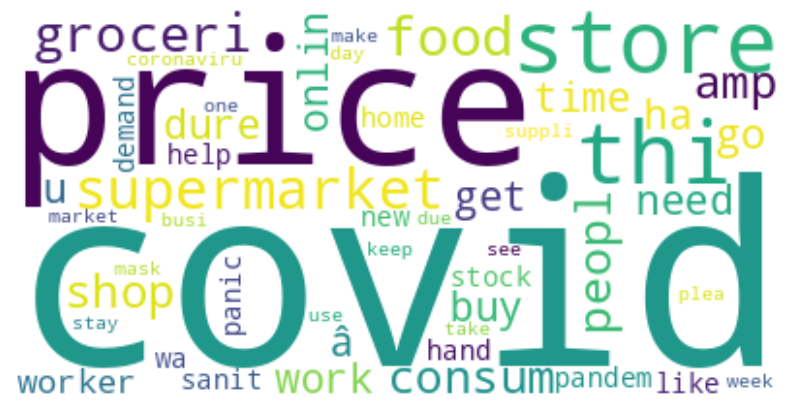

In [ ]:
# Generate wordcloud
wordcloud = WordCloud(
    collocations=False,
    background_color='white',
    stopwords=stopWords,
    max_words=50,
    max_font_size=200,
    random_state=12 #bebas
).generate(word)

# Tampilkan dan simpan
plt.figure(figsize=(10, 8))  # Buat figure baru dengan ukuran lebih besar
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

# Simpan ke file PNG sebelum plt.show()
plt.savefig("wordcloud_output.png", format='png', dpi=300, bbox_inches='tight')

# Tampilkan di layar
plt.show()

In [ ]:
# Import Library
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np

In [ ]:
data_word = [' '.join(tokens) for tokens in data_stop]

vectorizer = CountVectorizer(min_df=0.02)
x = vectorizer.fit_transform(data_word)
DTM = pd.DataFrame(x.toarray(), columns=vectorizer.get_feature_names_out())
DTM['kalimat_tweet'] = data_word
DTM['sum_features'] = DTM.select_dtypes(include=np.number).sum(axis=1)
DTM

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,kalimat_tweet,sum_features
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,advic talk neighbour famili exchang phone number creat contact list phone number neighbour school employ chemist gp set onlin shop account poss adequ suppli regular med order,5
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,coronaviru australia woolworth give elderli disabl dedic shop hour amid covid outbreak,5
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,food stock onli one empti pleas panic enough food everyon take need stay calm stay safe franc,13
4,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,readi go supermarket dure outbreak becaus paranoid becaus food stock litterali empti seriou thing pleas panic caus shortag,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,airlin pilot offer stock supermarket shelv lockdown,4
41153,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,respons complaint provid cite covid relat delay yet prompt reject polici befor consum tat way go,5
41154,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,know itâ get tough ration toilet paper martinsvil help us,6
41155,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,wrong smell hand sanit start turn,2


In [ ]:
vectorizer = CountVectorizer(min_df=0.02) #misal ada 100 dokumen, minimal 2 dokumen yang digunakan
data_word = [' '.join(tokens) for tokens in data_stop] # Join tokens to form strings
x = vectorizer.fit_transform(data_word)
raw_df = pd.DataFrame(x.toarray(), columns=vectorizer.get_feature_names_out())

LogTF = raw_df.applymap(lambda x: 1 + np.log(x) if x > 0 else 0)
LogTF['kalimat_tweet'] = data_word # Use data_word instead of data_stop
LogTF['sum_features'] = LogTF.select_dtypes(include=np.number).sum(axis=1)
LogTF

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,kalimat_tweet,sum_features
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,advic talk neighbour famili exchang phone number creat contact list phone number neighbour school employ chemist gp set onlin shop account poss adequ suppli regular med order,5.000000
2,0.0,1.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,coronaviru australia woolworth give elderli disabl dedic shop hour amid covid outbreak,5.000000
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,food stock onli one empti pleas panic enough food everyon take need stay calm stay safe franc,12.386294
4,0.0,0.0,0.0,0.0,0.0,1.693147,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,readi go supermarket dure outbreak becaus paranoid becaus food stock litterali empti seriou thing pleas panic caus shortag,10.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,airlin pilot offer stock supermarket shelv lockdown,4.000000
41153,0.0,0.0,0.0,0.0,0.0,0.000000,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,respons complaint provid cite covid relat delay yet prompt reject polici befor consum tat way go,5.000000
41154,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,know itâ get tough ration toilet paper martinsvil help us,6.000000
41155,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,wrong smell hand sanit start turn,2.000000


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np

vectorizer = CountVectorizer(min_df=0.02, binary=True) #misal ada 100 dokumen, minimal 2 dokumen yang digunakan
x = vectorizer.fit_transform(data_word)
BinaryTF = pd.DataFrame(x.toarray(), columns=vectorizer.get_feature_names_out())
BinaryTF['kalimat_tweet'] = data_word
BinaryTF['sum_features'] = BinaryTF.select_dtypes(include=np.number).sum(axis=1)
BinaryTF

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,kalimat_tweet,sum_features
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,advic talk neighbour famili exchang phone number creat contact list phone number neighbour school employ chemist gp set onlin shop account poss adequ suppli regular med order,5
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,coronaviru australia woolworth give elderli disabl dedic shop hour amid covid outbreak,5
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,food stock onli one empti pleas panic enough food everyon take need stay calm stay safe franc,11
4,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,readi go supermarket dure outbreak becaus paranoid becaus food stock litterali empti seriou thing pleas panic caus shortag,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,airlin pilot offer stock supermarket shelv lockdown,4
41153,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,respons complaint provid cite covid relat delay yet prompt reject polici befor consum tat way go,5
41154,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,know itâ get tough ration toilet paper martinsvil help us,6
41155,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,wrong smell hand sanit start turn,2


In [ ]:
# Gunakan raw count dulu
vectorizer = CountVectorizer(min_df=0.02) #misal ada 100 dokumen, minimal 2 dokumen yang digunakan
x = vectorizer.fit_transform(data_word)
raw_df = pd.DataFrame(x.toarray(), columns=vectorizer.get_feature_names_out())

# Hitung max TF per baris (dokumen)
max_tf = raw_df.max(axis=1)

# Rumus Augmented TF
AugTF = 0.5 + (raw_df.div(max_tf, axis=0) / 2)
AugTF['kalimat_tweet'] = data_stop
AugTF['sum_features'] = AugTF.select_dtypes(include=np.number).sum(axis=1)
AugTF

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,kalimat_tweet,sum_features
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[],0.00
1,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[advic, talk, neighbour, famili, exchang, phone, number, creat, contact, list, phone, number, neighbour, school, employ, chemist, gp, set, onlin, shop, account, poss, adequ, suppli, regular, med, order]",66.50
2,0.5,1.0,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[coronaviru, australia, woolworth, give, elderli, disabl, dedic, shop, hour, amid, covid, outbreak]",66.50
3,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[food, stock, onli, one, empti, pleas, panic, enough, food, everyon, take, need, stay, calm, stay, safe, franc]",67.25
4,0.5,0.5,0.5,0.5,0.5,1.0,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[readi, go, supermarket, dure, outbreak, becaus, paranoid, becaus, food, stock, litterali, empti, seriou, thing, pleas, panic, caus, shortag]",66.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[airlin, pilot, offer, stock, supermarket, shelv, lockdown]",66.00
41153,0.5,0.5,0.5,0.5,0.5,0.5,1.0,0.5,0.5,0.5,...,1.0,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[respons, complaint, provid, cite, covid, relat, delay, yet, prompt, reject, polici, befor, consum, tat, way, go]",66.50
41154,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[know, itâ, get, tough, ration, toilet, paper, martinsvil, help, us]",67.00
41155,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,"[wrong, smell, hand, sanit, start, turn]",65.00


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer=TfidfVectorizer(min_df=0.02)
vec=vectorizer.fit_transform(data_word)
TFIDF=pd.DataFrame(vec.toarray(),columns=vectorizer.get_feature_names_out())
TFIDF['kalimat_tweet']=data_word
TFIDF['sum_features'] = TFIDF.select_dtypes(include=np.number).sum(axis=1)
TFIDF

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,kalimat_tweet,sum_features
0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,,0.000000
1,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,advic talk neighbour famili exchang phone number creat contact list phone number neighbour school employ chemist gp set onlin shop account poss adequ suppli regular med order,2.210414
2,0.0,0.54879,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,coronaviru australia woolworth give elderli disabl dedic shop hour amid covid outbreak,2.177703
3,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,food stock onli one empti pleas panic enough food everyon take need stay calm stay safe franc,3.186889
4,0.0,0.00000,0.0,0.0,0.0,0.60559,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,readi go supermarket dure outbreak becaus paranoid becaus food stock litterali empti seriou thing pleas panic caus shortag,2.959889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,airlin pilot offer stock supermarket shelv lockdown,1.961010
41153,0.0,0.00000,0.0,0.0,0.0,0.00000,0.574203,0.0,0.0,0.0,...,0.542845,0.0,0.0,0.0,0.0,0.0,0.0,0.0,respons complaint provid cite covid relat delay yet prompt reject polici befor consum tat way go,2.167281
41154,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,know itâ get tough ration toilet paper martinsvil help us,2.440154
41155,0.0,0.00000,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,wrong smell hand sanit start turn,1.414206


In [ ]:
# Hitung IDF Manual
N = len(data_word)  # jumlah dokumen
df_term = (DTM.drop(columns='kalimat_tweet') > 0).sum(axis=0)  # df_t untuk tiap term
idf = np.log10(N / df_term) #terkadang ada yang ln juga, tergantung referensi

idf_df = pd.DataFrame({'term': idf.index, 'idf': idf.values})
idf_df

,term,idf
0,also,1.607978
1,amid,1.636720
2,amp,1.029322
3,ani,1.599084
4,back,1.681463
...,...,...
124,worker,1.248769
125,world,1.644562
126,would,1.594912
127,year,1.697464


In [ ]:
N

41157

In [ ]:
df_term

,0
also,1015
amid,950
amp,3847
ani,1036
back,857
...,...
worker,2321
world,933
would,1046
year,826


In [ ]:
# Buang kolom kalimat_tweet dulu biar bisa dikali dengan IDF
DTM_tf = DTM.drop(columns='kalimat_tweet')
BinaryTF_tf = BinaryTF.drop(columns='kalimat_tweet')
LogTF_tf = LogTF.drop(columns='kalimat_tweet')
AugTF_tf = AugTF.drop(columns='kalimat_tweet')

# Kalikan masing-masing TF dengan IDF
TFIDF_raw = DTM_tf.multiply(idf, axis=1)
TFIDF_binary = BinaryTF_tf.multiply(idf, axis=1)
TFIDF_log = LogTF_tf.multiply(idf, axis=1)
TFIDF_aug = AugTF_tf.multiply(idf, axis=1)

# Tambahkan kalimat tweet untuk kejelasan
TFIDF_raw['kalimat_tweet'] = data_stop
TFIDF_binary['kalimat_tweet'] = data_stop
TFIDF_log['kalimat_tweet'] = data_stop
TFIDF_aug['kalimat_tweet'] = data_stop

In [ ]:
TFIDF_raw

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,sum_features,kalimat_tweet
0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,[]
1,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[advic, talk, neighbour, famili, exchang, phone, number, creat, contact, list, phone, number, neighbour, school, employ, chemist, gp, set, onlin, shop, account, poss, adequ, suppli, regular, med, order]"
2,0.0,1.63672,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[coronaviru, australia, woolworth, give, elderli, disabl, dedic, shop, hour, amid, covid, outbreak]"
3,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.091829,"[food, stock, onli, one, empti, pleas, panic, enough, food, everyon, take, need, stay, calm, stay, safe, franc]"
4,0.0,0.00000,0.0,0.0,0.0,2.912162,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.077701,"[readi, go, supermarket, dure, outbreak, becaus, paranoid, becaus, food, stock, litterali, empti, seriou, thing, pleas, panic, caus, shortag]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.028255,"[airlin, pilot, offer, stock, supermarket, shelv, lockdown]"
41153,0.0,0.00000,0.0,0.0,0.0,0.000000,1.6912,0.0,0.0,0.0,...,1.57503,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[respons, complaint, provid, cite, covid, relat, delay, yet, prompt, reject, polici, befor, consum, tat, way, go]"
41154,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.042383,"[know, itâ, get, tough, ration, toilet, paper, martinsvil, help, us]"
41155,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.014128,"[wrong, smell, hand, sanit, start, turn]"


In [ ]:
TFIDF_binary

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,sum_features,kalimat_tweet
0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,[]
1,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[advic, talk, neighbour, famili, exchang, phone, number, creat, contact, list, phone, number, neighbour, school, employ, chemist, gp, set, onlin, shop, account, poss, adequ, suppli, regular, med, order]"
2,0.0,1.63672,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[coronaviru, australia, woolworth, give, elderli, disabl, dedic, shop, hour, amid, covid, outbreak]"
3,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.077701,"[food, stock, onli, one, empti, pleas, panic, enough, food, everyon, take, need, stay, calm, stay, safe, franc]"
4,0.0,0.00000,0.0,0.0,0.0,1.456081,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.070638,"[readi, go, supermarket, dure, outbreak, becaus, paranoid, becaus, food, stock, litterali, empti, seriou, thing, pleas, panic, caus, shortag]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.028255,"[airlin, pilot, offer, stock, supermarket, shelv, lockdown]"
41153,0.0,0.00000,0.0,0.0,0.0,0.000000,1.6912,0.0,0.0,0.0,...,1.57503,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[respons, complaint, provid, cite, covid, relat, delay, yet, prompt, reject, polici, befor, consum, tat, way, go]"
41154,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.042383,"[know, itâ, get, tough, ration, toilet, paper, martinsvil, help, us]"
41155,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.014128,"[wrong, smell, hand, sanit, start, turn]"


In [ ]:
TFIDF_log

,also,amid,amp,ani,back,becaus,befor,busi,buy,call,...,way,week,whi,work,worker,world,would,year,sum_features,kalimat_tweet
0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,[]
1,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[advic, talk, neighbour, famili, exchang, phone, number, creat, contact, list, phone, number, neighbour, school, employ, chemist, gp, set, onlin, shop, account, poss, adequ, suppli, regular, med, order]"
2,0.0,1.63672,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[coronaviru, australia, woolworth, give, elderli, disabl, dedic, shop, hour, amid, covid, outbreak]"
3,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.087494,"[food, stock, onli, one, empti, pleas, panic, enough, food, everyon, take, need, stay, calm, stay, safe, franc]"
4,0.0,0.00000,0.0,0.0,0.0,2.46536,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.075534,"[readi, go, supermarket, dure, outbreak, becaus, paranoid, becaus, food, stock, litterali, empti, seriou, thing, pleas, panic, caus, shortag]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41152,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.028255,"[airlin, pilot, offer, stock, supermarket, shelv, lockdown]"
41153,0.0,0.00000,0.0,0.0,0.0,0.00000,1.6912,0.0,0.0,0.0,...,1.57503,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035319,"[respons, complaint, provid, cite, covid, relat, delay, yet, prompt, reject, polici, befor, consum, tat, way, go]"
41154,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.042383,"[know, itâ, get, tough, ration, toilet, paper, martinsvil, help, us]"
41155,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0000,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.014128,"[wrong, smell, hand, sanit, start, turn]"


In [ ]:
# Fungsi untuk cari kata dengan bobot tertinggi secara keseluruhan
def find_top_weighted_words_global(tfidf_dict, top_n=1):
    """
    Finds the top weighted word(s) based on total weight across all documents.

    Args:
      tfidf_dict: Dictionary with key as method name and value as TF-IDF DataFrame.
      top_n: Number of top words to return (default is 1).

    Returns:
      Dictionary with method name as key and top word(s) as value.
    """
    top_words = {}
    for method_name, df in tfidf_dict.items():
        # Buang kolom non-fitur (seperti kalimat_tweet)
        df_features = df.drop(columns='kalimat_tweet')
        # Jumlahkan bobot dari semua dokumen untuk tiap kata
        total_weights = df_features.sum()
        max_weight = total_weights.max()
        # Simpan kata dengan bobot terbesar
        top_words[method_name] = [(word, weight) for word, weight in total_weights[total_weights == max_weight].items()]
    return top_words

# Gabungkan ke dalam satu dictionary
tfidf_variants = {
    'TFIDF_raw': TFIDF_raw,
    'TFIDF_binary': TFIDF_binary,
    'TFIDF_log': TFIDF_log,
    'TFIDF_aug': TFIDF_aug
}

# Jalankan fungsi
top_words_global = find_top_weighted_words_global(tfidf_variants)

# Cetak hasilnya
for method, words in top_words_global.items():
    print(f"Kata dengan bobot terbesar pada {method}: {words}")

Kata dengan bobot terbesar pada TFIDF_raw: [('price', 6480.816418362229)]
Kata dengan bobot terbesar pada TFIDF_binary: [('covid', 6213.557023591918)]
Kata dengan bobot terbesar pada TFIDF_log: [('covid', 6318.8242444548505)]
Kata dengan bobot terbesar pada TFIDF_aug: [('year', 34947.38190413028)]
